In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/pbl_hoaks_valid_clean.csv')
print('Dimensi data:', df.shape)
print('Distribusi kelas target (1: Hoaks, 0: Valid):')
print(df['label'].value_counts())
df.head()


Dimensi data: (1498, 2)
Distribusi kelas target (1: Hoaks, 0: Valid):
label
1    749
0    749
Name: count, dtype: int64


,teks_bersih,label
0,presiden prabowo minta maaf ikut bop akan kemb...,1
1,video presiden prabowo akan membagikan bantuan...,1
2,pemerintah kota tangerang selatan akan legalka...,1
3,tautan rekrutmen cpns kementerian imigrasi,1
4,ramuan rebusan jahe kunyit kencur dan serai be...,1


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X_raw = df['teks_bersih']
y = df['label'].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(max_features=1000)
X_train = tfidf.fit_transform(X_train_raw).toarray().astype('float32')
X_test = tfidf.transform(X_test_raw).toarray().astype('float32')

print('Dimensi data latih:', X_train.shape)
print('Dimensi data uji  :', X_test.shape)


Dimensi data latih: (1198, 1000)
Dimensi data uji  : (300, 1000)


In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

tf.random.set_seed(42)

# Model JST
model_pbl = Sequential([
    Dense(128, activation='relu', input_shape=(1000,)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model_pbl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_pbl.summary()


C:\Users\azure\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       128,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,449 (533.00 KB)

 Trainable params: 136,449 (533.00 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model_pbl.fit(
    X_train, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/25


 1/30 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.4375 - loss: 0.7011

13/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5553 - loss: 0.6901

26/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6034 - loss: 0.6840

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6159 - loss: 0.6826

30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.6159 - loss: 0.6826 - val_accuracy: 0.8333 - val_loss: 0.6626


... (108 outputs left out)

 1/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 1.0000 - loss: 4.8768e-04

14/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 6.5703e-04 

29/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 6.4588e-04

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 6.3850e-04 - val_accuracy: 0.9000 - val_loss: 0.3153


In [5]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Evaluasi loss dan akurasi
test_loss, test_acc = model_pbl.evaluate(X_test, y_test, verbose=0)
print(f'Loss Data Uji    : {test_loss:.4f}')
print(f'Akurasi Data Uji : {test_acc * 100:.2f}%')
print()

# Prediksi kelas biner (threshold 0.5)
y_pred_prob = model_pbl.predict(X_test)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print('Classification Report JST:')
print(classification_report(y_test, y_pred, target_names=['Valid', 'Hoaks']))


Loss Data Uji    : 0.4818
Akurasi Data Uji : 87.67%



 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


Classification Report JST:
              precision    recall  f1-score   support

       Valid       0.88      0.87      0.88       150
       Hoaks       0.87      0.89      0.88       150

    accuracy                           0.88       300
   macro avg       0.88      0.88      0.88       300
weighted avg       0.88      0.88      0.88       300



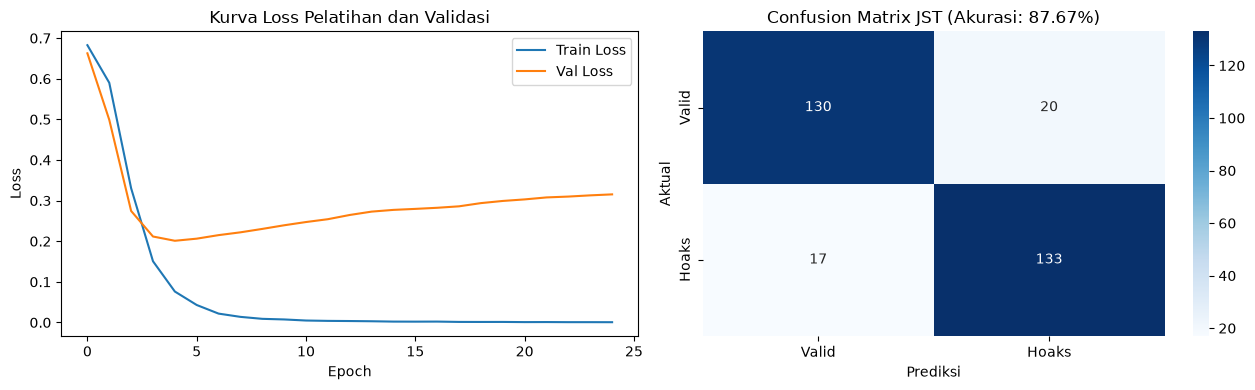

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Kurva Loss
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Kurva Loss Pelatihan dan Validasi')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Valid', 'Hoaks'], yticklabels=['Valid', 'Hoaks'])
axes[1].set_title(f'Confusion Matrix JST (Akurasi: {test_acc*100:.2f}%)')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()
